In [ ]:
# prompt: export pretrained keras mobilenet model to tflite, quantize to INT8

import tensorflow as tf

# download the weights from
# https://github.com/NavodPeiris/MobileNet_96x96_greyscale_weights
!wget https://raw.githubusercontent.com/NavodPeiris/MobileNet_96x96_greyscale_weights/main/mobilenetV1_0.1_96x96_greyscale_weights.h5
!wget https://raw.githubusercontent.com/NavodPeiris/MobileNet_96x96_greyscale_weights/main/mobilenetV1_0.2_96x96_greyscale_weights.h5
!wget https://raw.githubusercontent.com/NavodPeiris/MobileNet_96x96_greyscale_weights/main/mobilenetV1_0.25_96x96_greyscale_weights.h5

--2026-11-09 09:28:42--  https://raw.githubusercontent.com/NavodPeiris/MobileNet_96x96_greyscale_weights/main/mobilenetV1_0.1_96x96_greyscale_weights.h5
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 368876 (360K) [application/octet-stream]
Saving to: ‘mobilenetV1_0.1_96x96_greyscale_weights.h5’

mobilenetV1_0.1_96x 100%[===================>] 360.23K  --.-KB/s    in 0.005s  

2026-11-09 09:28:43 (71.3 MB/s) - ‘mobilenetV1_0.1_96x96_greyscale_weights.h5’ saved [368876/368876]

--2026-11-09 09:28:43--  https://raw.githubusercontent.com/NavodPeiris/MobileNet_96x96_greyscale_weights/main/mobilenetV1_0.2_96x96_greyscale_weights.h5
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting 

In [ ]:
# Load custom data set


from google.colab import files
uploaded = files.upload()


Saving yes_no_dataset.zip to yes_no_dataset.zip
ls: cannot access '/content/yes_no_dataset': No such file or directory


In [ ]:
!unzip -q yes_no_dataset.zip -d /content/
!ls /content/yes_no_dataset/

no  yes


In [ ]:
IMAGE_SIZE = 96
BATCH_SIZE = 32
EPOCHS = 100
COLOR_MODE = "grayscale"
DATASET_DIR = "/content/yes_no_dataset"

dataset = tf.keras.preprocessing.image_dataset_from_directory(
    DATASET_DIR,
    shuffle=True,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    color_mode=COLOR_MODE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

print("Class names:", dataset.class_names)

def get_data_splitting_tf(dataset,
                      train_split = 0.7,
                      test_split = 0.15,
                      val_split = 0.15,
                      shuffle = True, # data will be shuffle show that no particular image in sellected more than once durring the splitting
                      shuffle_size = 100000 #
                      ):


    data_size = len(dataset)
    if shuffle:

        dataset = dataset.shuffle(shuffle_size, seed = 42)
    train_size = int(train_split * data_size)

    test_size = int(test_split * data_size)

    train_dataset = dataset.take(train_size)
    test_dataset = dataset.skip(train_size).take(test_size) # the test data will skip the data in the train dataset

    val_dataset = dataset.skip(train_size).skip(test_size) # this will also skip all the dataset that has already been selected by the test and train size

    return train_dataset, test_dataset, val_dataset

train_dataset , test_dataset , val_dataset = get_data_splitting_tf(dataset)

train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)
test_dataset = test_dataset.cache().shuffle(1000).prefetch(buffer_size =  tf.data.AUTOTUNE)
val_dataset = val_dataset.cache().shuffle(1000).prefetch(buffer_size = tf.data.AUTOTUNE)

rescale_and_resize = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1.0/255)
]) # Rescale and resizing the data

# Data augmentation is done toe to introduce the data to different orrientations and also increase the size of the dataset

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("Horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.3)
    ], name="data_augmentation")

Found 1000 files belonging to 2 classes.
Class names: ['no', 'yes']


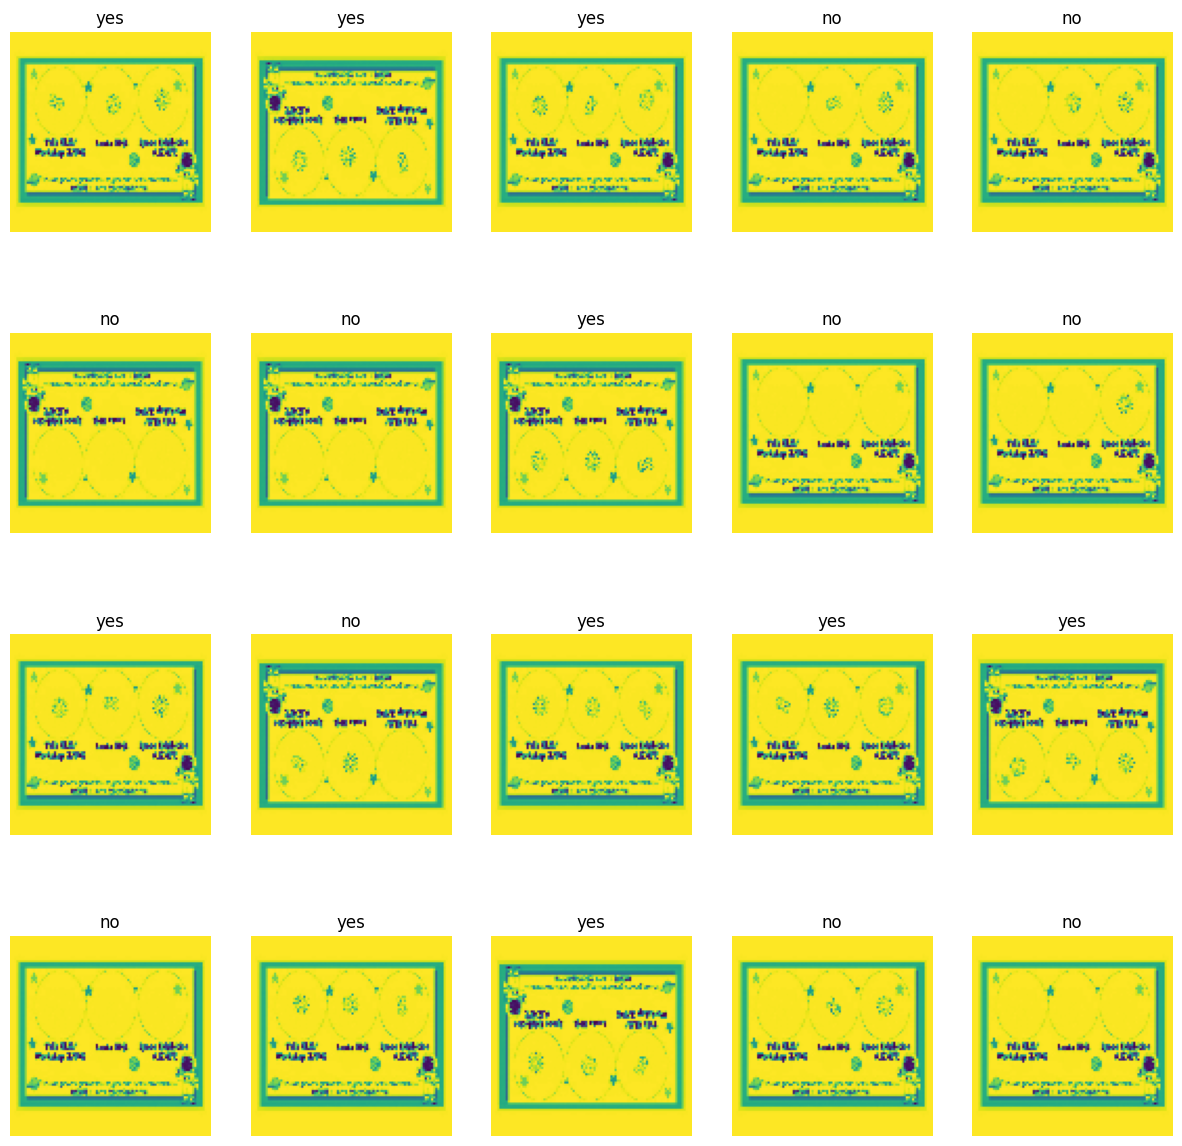

In [ ]:
class_names = dataset.class_names

import matplotlib.pyplot as plt

plt.figure(figsize = (15, 15))

for image_batch, label_batch in dataset.take(1):
    for j in range(20): # Showing 20 images from among the dadtaset in the two classes
        ax = plt.subplot(4,5, j+1)
        plt.imshow(image_batch[j].numpy().astype("uint8"))
        plt.title(class_names[label_batch[j].numpy().argmax()])

        plt.axis(False) # do not show axis for the images

In [ ]:
# clear keras session
tf.keras.backend.clear_session()

input_tensor = tf.keras.layers.Input(shape=(96, 96, 1))
aug = data_augmentation(input_tensor)

mobilenet_model = tf.keras.applications.MobileNet(
    input_shape=(96, 96, 1),
    input_tensor=aug,
    pooling="avg",
    alpha=0.1,   # 0.25, 0.2, 0.1
    weights="mobilenetV1_0.1_96x96_greyscale_weights.h5", # 0.25, 0.2, 0.1
    include_top=False
    )

mobilenet_model.trainable = False

mobilenet_output = mobilenet_model.output

# classification layer
classification_layer = tf.keras.layers.Dense(2, activation='softmax')(mobilenet_output)

model = tf.keras.Model(inputs=mobilenet_model.input, outputs=classification_layer)

print("Compiling model...")
model.compile(loss="categorical_crossentropy",
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                metrics=["accuracy"])

model.summary()

Compiling model...


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 48, 48, 3)      │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_bn (BatchNormalization)   │ (None, 48, 48, 3)      │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_relu (ReLU)               │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1 (DepthwiseConv2D)     │ (None, 48, 48, 3)      │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_bn                    │ (None, 48, 48, 3)      │            12 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_1_relu (ReLU)           │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1 (Conv2D)              │ (None, 48, 48, 6)      │            18 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_bn                    │ (None, 48, 48, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_1_relu (ReLU)           │ (None, 48, 48, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pad_2 (ZeroPadding2D)      │ (None, 49, 49, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2 (DepthwiseConv2D)     │ (None, 24, 24, 6)      │            54 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_bn                    │ (None, 24, 24, 6)      │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_2_relu (ReLU)           │ (None, 24, 24, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2 (Conv2D)              │ (None, 24, 24, 12)     │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_bn                    │ (None, 24, 24, 12)     │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_2_relu (ReLU)           │ (None, 24, 24, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3 (DepthwiseConv2D)     │ (None, 24, 24, 12)     │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_bn                    │ (None, 24, 24, 12)     │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_dw_3_relu (ReLU)           │ (None, 24, 24, 12)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_pw_3 (Conv2D)              │ (None, 24, 24, 12)     │           144 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 40,033 (156.38 KB)

 Trainable params: 206 (824.00 B)

 Non-trainable params: 39,827 (155.57 KB)

In [ ]:
history = model.fit(
                   train_dataset,
                   epochs = EPOCHS,
                   batch_size = BATCH_SIZE,
                   verbose = 1,
                   validation_data = val_dataset
                   )

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 171ms/step - accuracy: 0.4868 - loss: 1.1345 - val_accuracy: 0.4688 - val_loss: 0.8808
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.4765 - loss: 0.9133 - val_accuracy: 0.4688 - val_loss: 1.0475
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.5000 - loss: 0.8338 - val_accuracy: 0.4688 - val_loss: 0.8946
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.5221 - loss: 0.7896 - val_accuracy: 0.4688 - val_loss: 0.8812
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.5029 - loss: 0.7770 - val_accuracy: 0.4688 - val_loss: 0.8688
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.5441 - loss: 0.7355 - val_accuracy: 0.4688 - val_loss: 0.7997
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.5235 - loss: 0.7222 - val_accuracy: 0.4688 - val_loss: 0.7925
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.5735 - loss: 0.6931 - val_accuracy:

In [ ]:
def representative_dataset():
    for images, _ in train_dataset.take(100):
        yield [tf.cast(images, tf.float32)]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_model_quant = converter.convert()
# Save the quantized model
with open('model_quant.tflite', 'wb') as f:
  f.write(tflite_model_quant)

Saved artifact at '/tmp/tmp6a11nru_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  140717168031312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169633680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169635600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169394320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169406416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169406224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169627344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169635984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169627536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169627728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140717169635792:

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


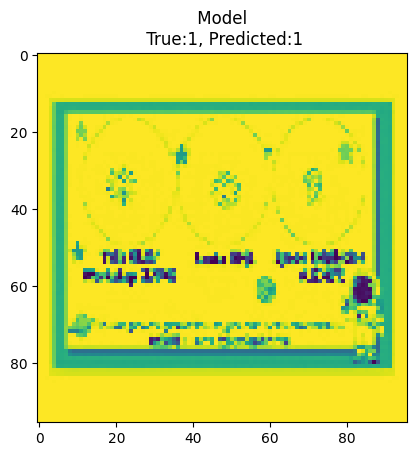

In [ ]:
import numpy as np

# Helper function to run inference on a TFLite model
def run_tflite_model(tflite_file, test_images):

  # Initialize the interpreter
  interpreter = tf.lite.Interpreter(model_path=str(tflite_file))
  interpreter.allocate_tensors()

  input_details = interpreter.get_input_details()[0]
  output_details = interpreter.get_output_details()[0]

  predictions = np.zeros((len(test_images),), dtype=int)
  for i, test_image in enumerate(test_images):

    # Check if the input type is quantized, then rescale input data to uint8
    if input_details['dtype'] == np.int8:
      input_scale, input_zero_point = input_details["quantization"]
      test_image = test_image / input_scale + input_zero_point

    test_image = np.expand_dims(test_image, axis=0).astype(input_details["dtype"])
    interpreter.set_tensor(input_details["index"], test_image)
    interpreter.invoke()
    output = interpreter.get_tensor(output_details["index"])[0]

    predictions[i] = output.argmax()

  return predictions

# Change this to test a different image
test_image_index = np.random.randint(0, BATCH_SIZE)

## Helper function to test the models on one image
def test_model(tflite_file, test_image_index):

  # take one image from test dataset
  test_data = list(test_dataset.take(2).as_numpy_iterator())[0]
  test_image = test_data[0][test_image_index]
  test_label = test_data[1][test_image_index]
  predictions = run_tflite_model(tflite_file, [test_image])
  plt.imshow(test_image)
  template = " Model \n True:{true}, Predicted:{predict}"
  _ = plt.title(template.format(true = str(test_label.argmax()), predict=str(predictions[0])))
  plt.grid(False)

test_model('model_quant.tflite', test_image_index)

In [ ]:
def evaluate_model(tflite_file):

  test_data = list(test_dataset.take(1).as_numpy_iterator())[0]
  test_images = test_data[0]
  test_labels = test_data[1].argmax(axis=1)
  predictions = run_tflite_model(tflite_file, test_images)

  accuracy = (np.sum(test_labels==predictions) * 100) / len(test_images)

  print('model accuracy is %.4f%% (Number of test samples=%d)' % (accuracy, len(test_images)))

evaluate_model('model_quant.tflite')

model accuracy is 78.1250% (Number of test samples=32)


In [ ]:
!xxd -i  model_quant.tflite > model.h

/bin/bash: line 1: xxd: command not found
